<a href="https://colab.research.google.com/github/vicradon/emotion-detection/blob/main/emotion_detection_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ultralytics==8.2.103 -q

from IPython import display
display.clear_output()

!yolo settings sync=False

import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 38.6/112.6 GB disk)


In [2]:
from ultralytics import YOLO

from IPython.display import display, Image

In [3]:
!pip install -q roboflow

from roboflow import Roboflow
from google.colab import userdata
roboflow_api_key = userdata.get('roboflow_api_key')

rf = Roboflow(api_key=roboflow_api_key)

project = rf.workspace("test-lstpy").project("emotion-gyup3-j130x")
version = project.version(1)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 61.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 87.0 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to emotion-1 in yolov8:: 100%|██████████| 6536/6536 [00:00<00:00, 8237.39it/s]


In [4]:
!yolo task=detect mode=train model=yolov8s.pt data={dataset.location}/data.yaml epochs=50 imgsz=640 plots=True

100% 21.5M/21.5M [00:01<00:00, 20.7MB/s]
New https://pypi.org/project/ultralytics/8.3.235 available 😃 Update with 'pip install -U ultralytics'
Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=detect, mode=train, model=yolov8s.pt, data=/content/emotion-1/data.yaml, epochs=50, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina

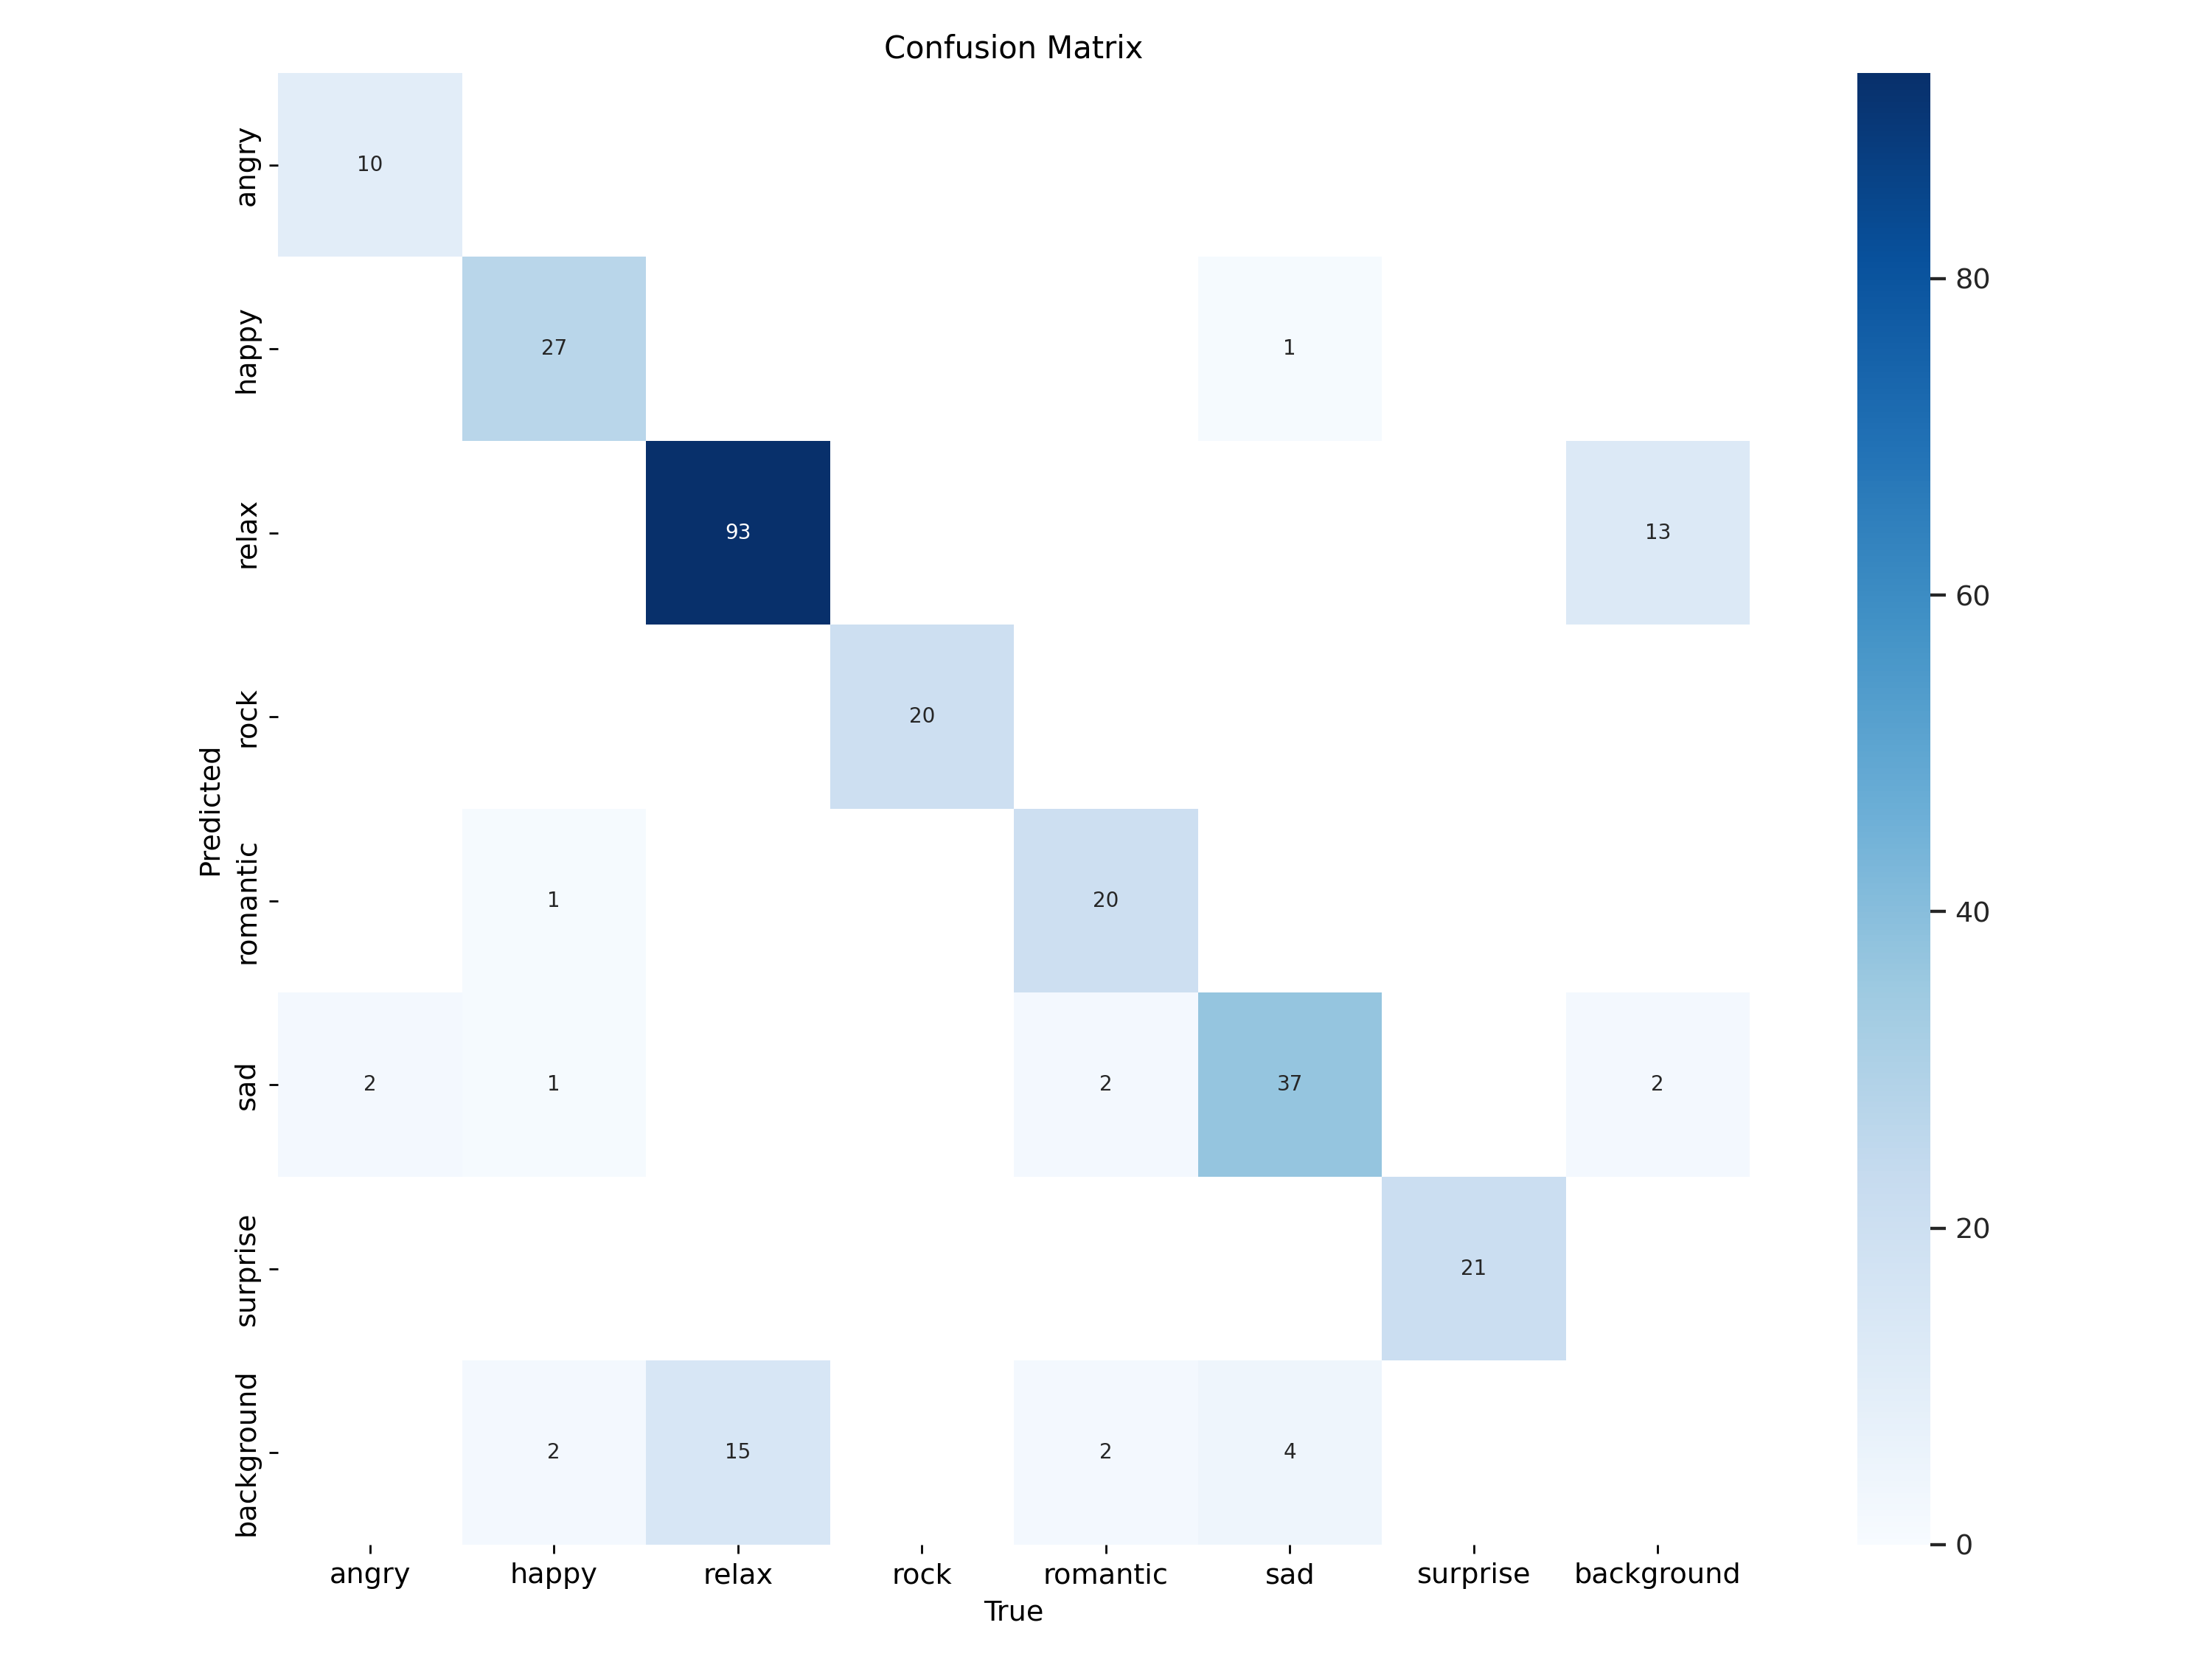

In [7]:
Image(filename=f'/content/runs/detect/train/confusion_matrix.png', width=600)

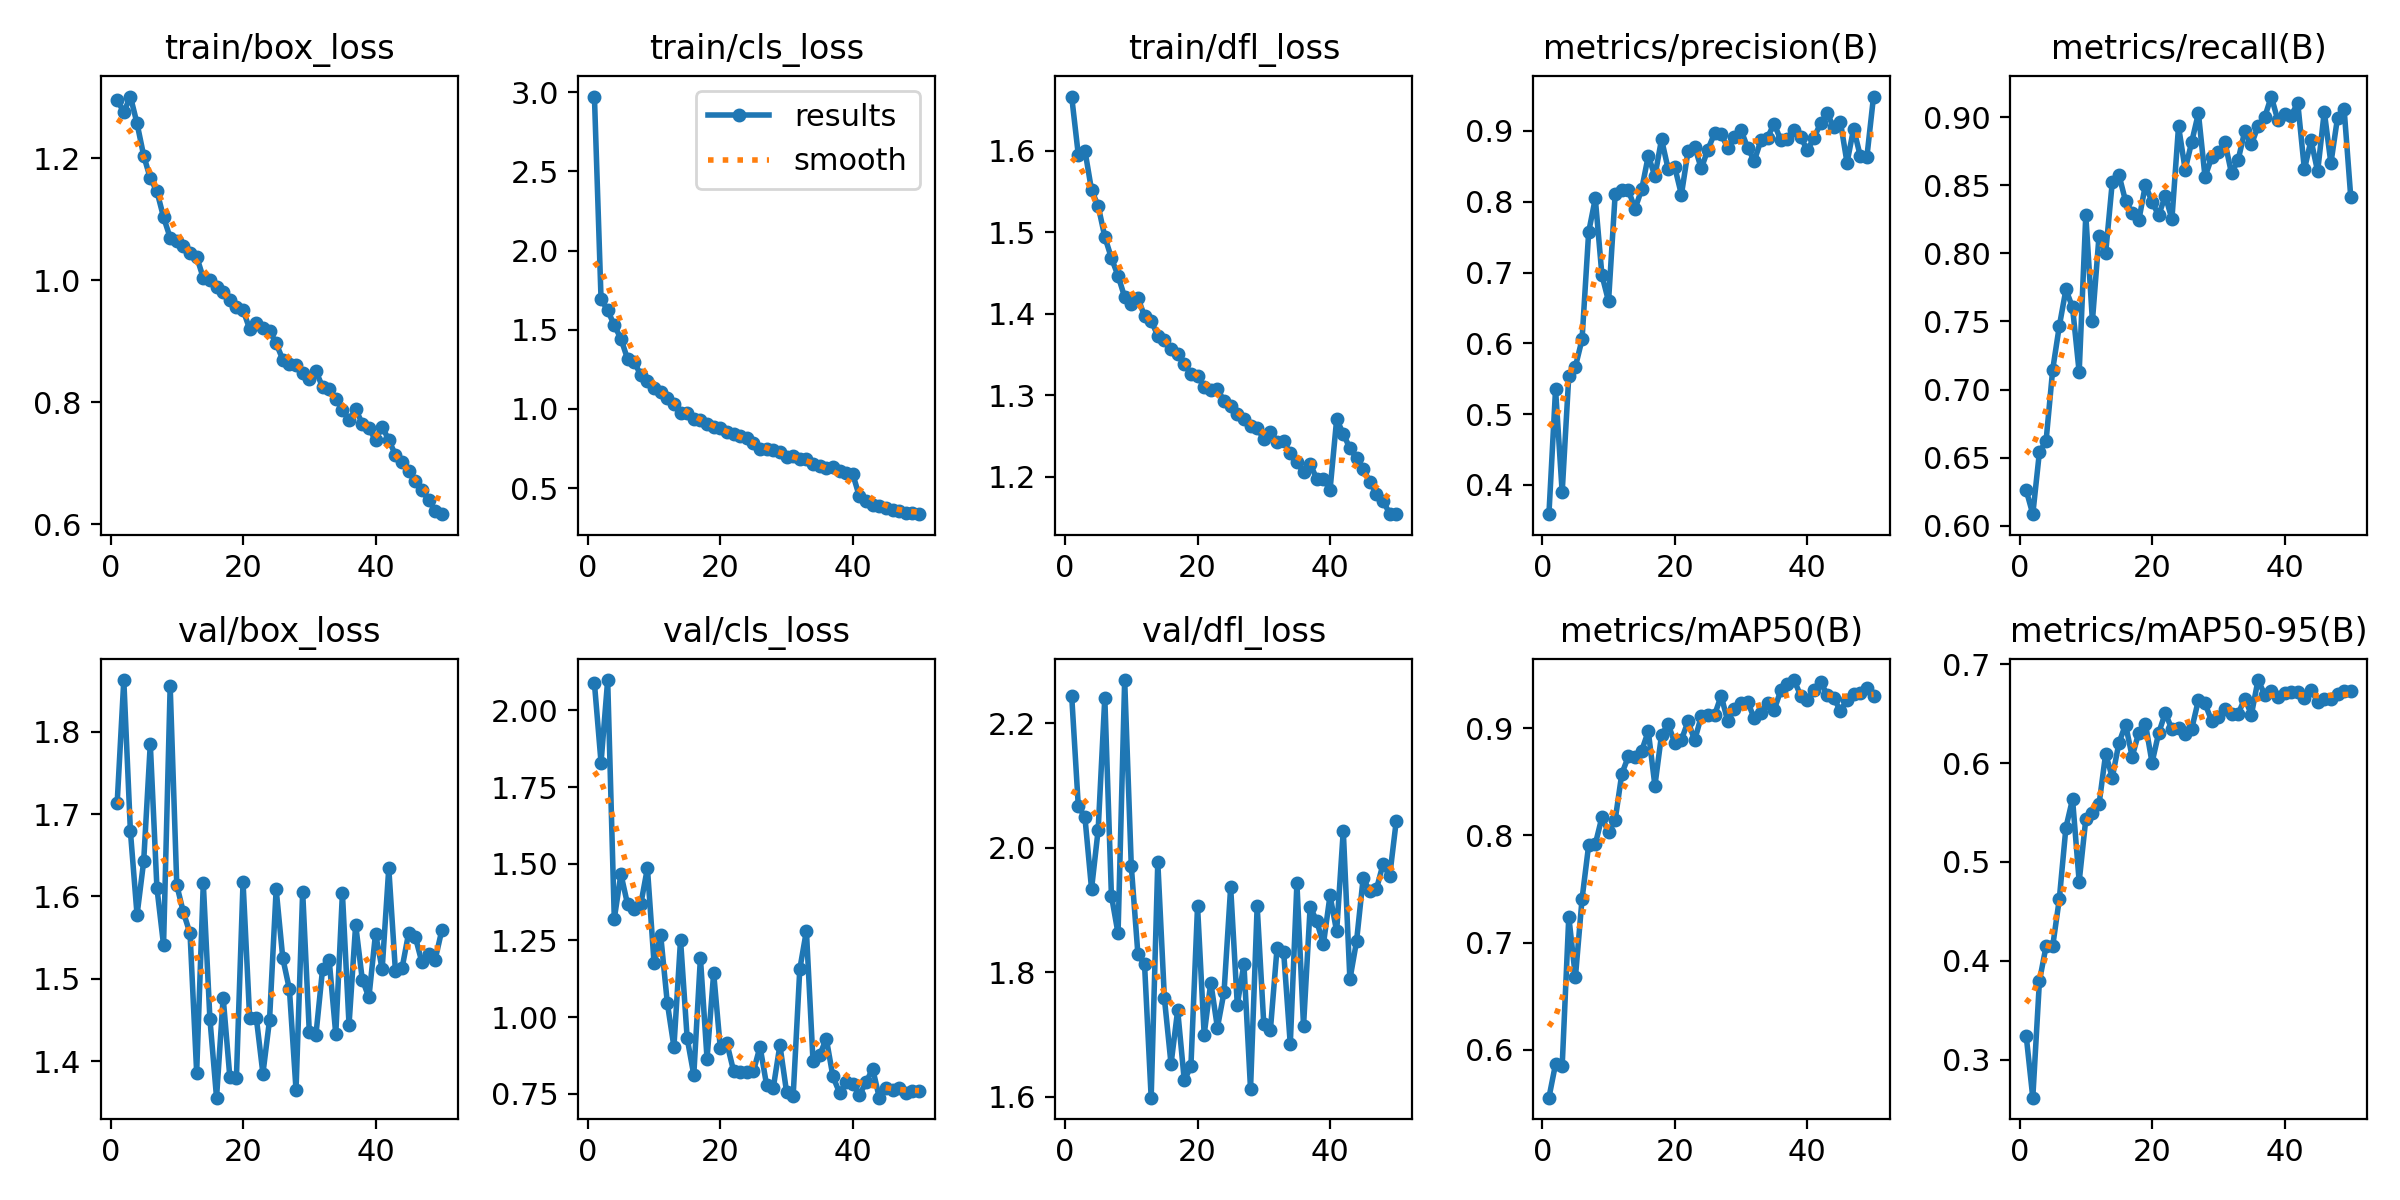

In [8]:
Image(filename=f'/content/runs/detect/train/results.png', width=1200)

In [9]:
!yolo task=detect mode=val model=/content/runs/detect/train/weights/best.pt data={dataset.location}/data.yaml

Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 168 layers, 11,128,293 parameters, 0 gradients, 28.5 GFLOPs
val: Scanning /content/emotion-1/valid/labels.cache... 225 images, 15 backgrounds, 0 corrupt: 100% 225/225 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 15/15 [00:03<00:00,  3.84it/s]
                   all        225        258      0.887      0.893      0.935      0.686
                 angry         12         12      0.832      0.833      0.905       0.71
                 happy         31         31      0.923      0.871      0.955      0.761
                 relax         60        108       0.88      0.843      0.885      0.424
                  rock         20         20      0.966          1      0.995      0.674
              romantic         24         24      0.952      0.825      0.947       0.75
                   sad         42         42 

In [11]:
!yolo task=detect mode=predict model=/content/runs/detect/train/weights/best.pt conf=0.25 source={dataset.location}/test/images save=True

Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 168 layers, 11,128,293 parameters, 0 gradients, 28.5 GFLOPs

image 1/183 /content/emotion-1/test/images/-_jpg.rf.9b4a19738da66a5236634babad9400ea.jpg: 640x640 1 romantic, 16.2ms
image 2/183 /content/emotion-1/test/images/080307-f-3961f-002_jpg.rf.11fe1d338503c42215443981d4890b31.jpg: 640x640 1 rock, 16.3ms
image 3/183 /content/emotion-1/test/images/0b136497e50a7ccb63deae5dc188bc3075fe6f1b2fef998960d84e72_jpg.rf.f8eec8b03f9122f4767bf86f0ed31d50.jpg: 640x640 1 happy, 16.2ms
image 4/183 /content/emotion-1/test/images/0bb786958031887d6d36a1dbd4380d94dd68a0064b1f060a6e0de682_jpg.rf.7130978e1c3bd51a770988930fa3290e.jpg: 640x640 1 relax, 1 sad, 16.3ms
image 5/183 /content/emotion-1/test/images/0bbd74657766d5c1c2f451e40260fb7765f8908f4f8fcba57c21b8be_jpg.rf.418b065b4406bb46487ecaac3b2ed5c3.jpg: 640x640 1 angry, 1 sad, 16.2ms
image 6/183 /content/emotion-1/test/images/0bf5df53a229365df

**NOTE:** Let's take a look at few results.

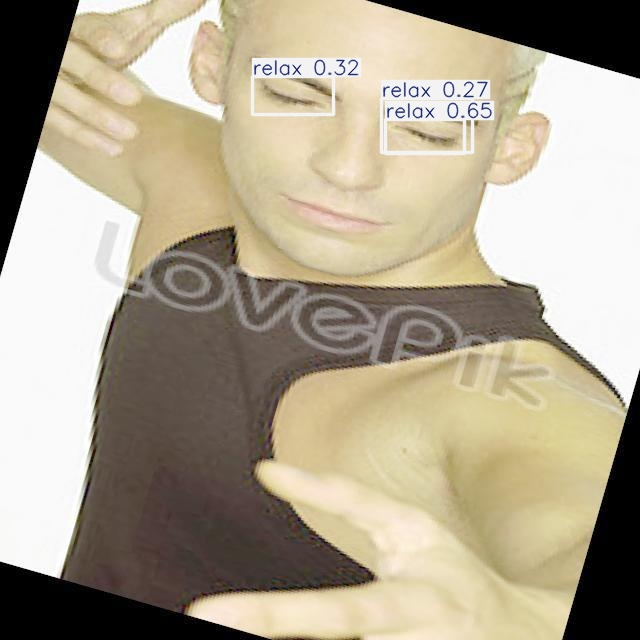

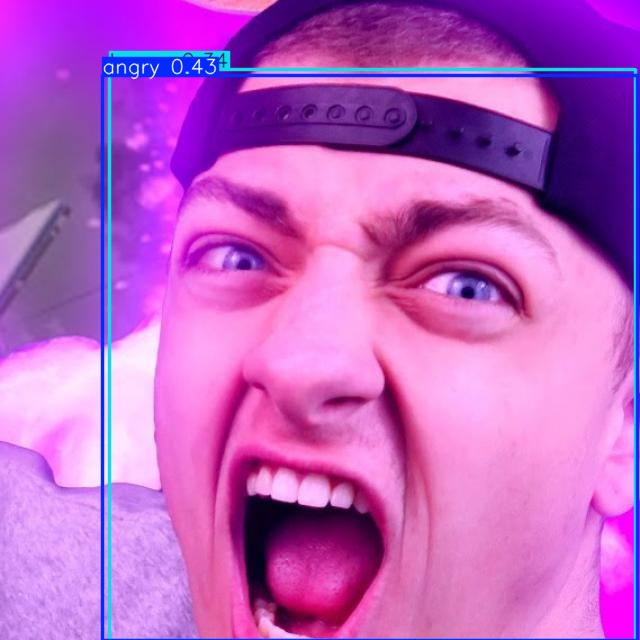

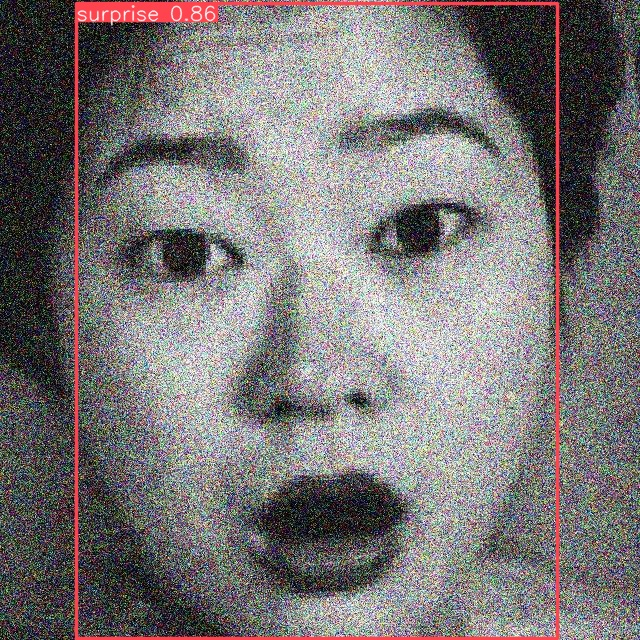

In [12]:
import os
import glob
from IPython.display import Image, display

# Define the base path where the folders are located
base_path = '/content/runs/detect/'

# List all directories that start with 'predict' in the base path
subfolders = [os.path.join(base_path, d) for d in os.listdir(base_path)
              if os.path.isdir(os.path.join(base_path, d)) and d.startswith('predict')]

# Find the latest folder by modification time
latest_folder = max(subfolders, key=os.path.getmtime)

image_paths = glob.glob(f'{latest_folder}/*.jpg')[:3]

# Display each image
for image_path in image_paths:
    display(Image(filename=image_path, width=600))
    print("\n")